In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [70]:
mapping_tech = {
    "ATAC": "ATAC",
    "CATS RNAseq": "Others",
    "CITE-seq": "CITE-seq",
    "ChIPseq": "ChIPseq",
    "Cut&Run-Seq": "Others",
    "Cut&Tag-Seq": "Others",
    "Hi-C": "Others",
    "Hydroxmethylation": "Others",
    "MaasHPS": "Others",
    "MeDIPseq": "Others",
    "Methylation": "Others",
    "Microarray": "Microarray",
    "RNAseq": "RNAseq",
    "SMARTseq": "Others",
    "Visium": "spatial",
    "Xenium": "spatial",
    "circRNAseq": "Others",
    "eCLIP": "Others",
    "miRNAseq": "miRNAseq",
    "scRNAseq": "scRNAseq",
    "smRNAseq": "Others",
    "snRNAseq": "Others"
}
mapping_species = {
    "Mouse": "Mouse",
    "Human": "Human",
    "Rattus norvegicus": "Rattus norvegicus",
    "Sus scrofa": "Sus scrofa",
    "Baboon": "Others",
    "Danio rerio": "Others"
}
mapping_species_coarse = {
    "Mouse": "Mouse",
    "Human": "Human",
    "Rattus norvegicus": "Others",
    "Sus scrofa": "Sus scrofa",
    "Baboon": "Others",
    "Danio rerio": "Others"
}

palette_tech = {
    "ATAC": 'tab:blue',
    "CITE-seq": 'tab:orange',
    "ChIPseq": 'tab:green',
    "Microarray": 'tab:red',
    "RNAseq": 'tab:purple',
    "miRNAseq": 'tab:brown',
    "scRNAseq": 'tab:pink',
    "spatial": 'tab:olive',
    "Others": 'tab:cyan'
}

palette_species = {
    "Human": 'tab:blue',
    "Mouse": 'tab:orange',
    "Rattus norvegicus": 'tab:red',
    "Sus scrofa": 'tab:green',
    "Others": 'tab:cyan'
}

In [95]:
datasets = pd.read_excel(r"C:\Users\jonas\OneDrive\Desktop\Semester_4_Bio\Masterpraktikum\Dataset_collection.xlsx", sheet_name="Jonas", header=1, index_col=0).reset_index()
datasets['agg_technology'] = datasets['Technologie'].map(mapping_tech)
datasets['agg_species_coarse'] = datasets['Species'].map(mapping_species_coarse)
datasets['agg_species'] = datasets['Species'].map(mapping_species)
datasets.head()

,index,Dataset,Technologie,Device,Library,Species,samples,plaque phenotype,plaque calcification,location,...,KO,age,comments,celltype,Paper Titel,Experiment,Date,agg_technology,agg_species_coarse,agg_species
0,NaN,GSE309462,scRNAseq,NovaSeq 6000,SeekOne MM Single Cell 3' library,Mouse,2,NaN,NaN,"carotid bifurcation, common caritid",...,WT,NaN,NaN,plaque,Endothelial BMP6 Drives Hemodynamic-Dependent ...,12 CAS plaques obtained following carotid enda...,2025-10-03 00:00:00,scRNAseq,Mouse,Mouse
1,NaN,GSE309462,scRNAseq,NovaSeq 6000,SeekOne MM Single Cell 3' library,Human,12,symptomatic vs asymptomatic,high vs low calcification,carotid artery plaques,...,NaN,NaN,NaN,plaque,Endothelial BMP6 Drives Hemodynamic-Dependent ...,12 CAS plaques obtained following carotid enda...,2025-10-03 00:00:00,scRNAseq,Human,Human
2,NaN,GSE255895,snRNAseq,NovaSeq 6000,10x Genomics Single Nucleus 3',Human,12,NaN,NaN,Internal thoratic artery,...,NaN,"m: ~63, f~77",NaN,plaque,Senescence and Inflamm-Aging Are Associated Wi...,Nuclei were isolated from internal thoracic ar...,2024-09-04 00:00:00,Others,Human,Human
3,NaN,GSE246138,scRNAseq,HiSeq 4000,Chromium Single Cell 3' Kit; V3 Chemistry,Mouse,2,pre-plaque development,NaN,whole aorta,...,"1WT, 1 ATGL ECKO",NaN,FACS sorting for viable cells,FACSs,Dynamic metabolism of endothelial triglyceride...,Endothelial specefic ATGL knockout (ATGL ECKO)...,2023-10-31 00:00:00,scRNAseq,Mouse,Mouse
4,NaN,GSE311726,snRNAseq,Novaseq X,NaN,Mouse,4,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,Not published,We assess whether endMT is observed in vivo du...,2025-12-22 00:00:00,Others,Mouse,Mouse


In [125]:
datasets.to_csv("Jonas_datasets.tsv", sep="\t")

In [126]:
datasets.to_excel("Jonas_datasets.xlsx")

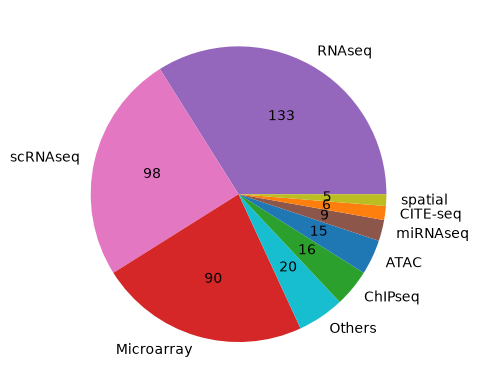

In [96]:
tech_distr = datasets.groupby("agg_technology").size()
tech_distr = tech_distr.sort_values(ascending=False)
fig, ax = plt.subplots()
total_ds = sum(tech_distr.values)
color = [palette_tech[x] for x in tech_distr.index]
ax.pie(tech_distr.values, labels=list(tech_distr.index), autopct=lambda p: f'{round(p * total_ds / 100):d}', colors=color)

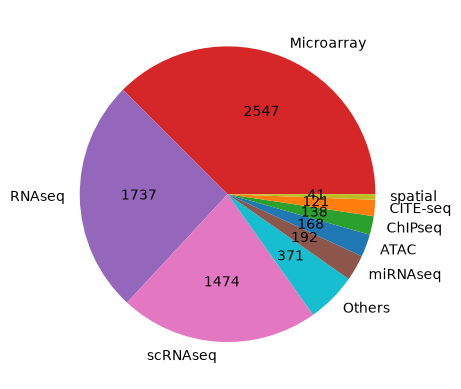

In [97]:
datasets_tmp = datasets[datasets['Dataset']!="E-MTAB-3732"]
tech_distr_sample = datasets_tmp.groupby("agg_technology").sum("samples")
tech_distr_sample = tech_distr_sample.sort_values(by="samples", ascending=False)
fig, ax = plt.subplots()
color = [palette_tech[x] for x in tech_distr_sample.index]
total_ds = sum(tech_distr_sample['samples'])
ax.pie(tech_distr_sample['samples'], labels=list(tech_distr_sample.index), autopct=lambda p: f'{round(p * total_ds / 100):d}', colors=color)

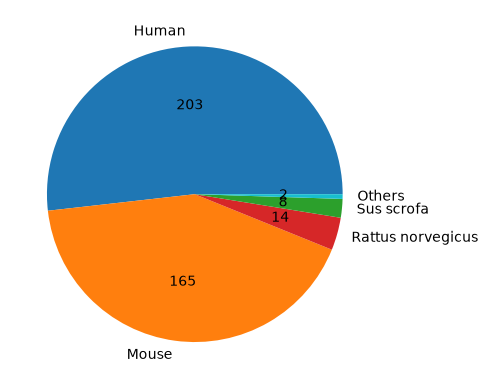

In [98]:
species_distr = datasets.groupby("agg_species").size()
species_distr = species_distr.sort_values(ascending=False)
fig, ax = plt.subplots()
total_ds = sum(species_distr.values)
color = [palette_species[x] for x in species_distr.index]
ax.pie(species_distr.values, labels=list(species_distr.index), autopct=lambda p: f'{round(p * total_ds / 100):d}', colors=color)

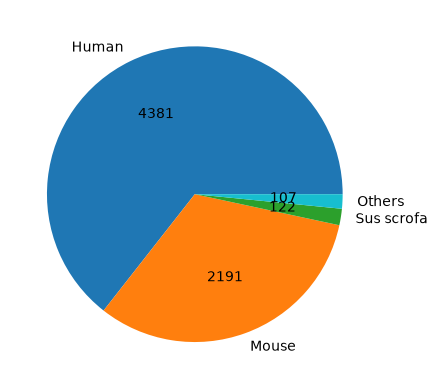

In [99]:
datasets_tmp = datasets[datasets['Dataset']!="E-MTAB-3732"]
species_distr_sample = datasets_tmp.groupby("agg_species_coarse").sum("samples")
species_distr_sample = species_distr_sample.sort_values(by="samples", ascending=False)
fig, ax = plt.subplots()
total_ds = sum(species_distr_sample['samples'])
color = [palette_species[x] for x in species_distr_sample.index]
ax.pie(species_distr_sample['samples'], labels=list(species_distr_sample.index), autopct=lambda p: f'{round(p * total_ds / 100):d}', colors=color)

In [100]:
datasets_rnaseq = datasets[datasets['Technologie']=="RNAseq"]

133


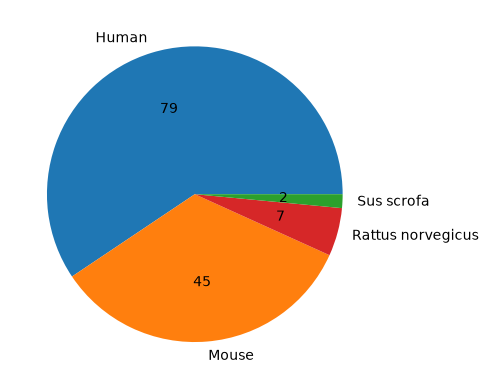

In [101]:
species_distr_rnaseq = datasets_rnaseq.groupby("agg_species").size()
species_distr_rnaseq = species_distr_rnaseq.sort_values(ascending=False)
fig, ax = plt.subplots()
total_ds = sum(species_distr_rnaseq.values)
print(total_ds)
color = [palette_species[x] for x in species_distr_rnaseq.index]
ax.pie(species_distr_rnaseq.values, labels=list(species_distr_rnaseq.index), autopct=lambda p: f'{round(p * total_ds / 100):d}', colors=color)

1737


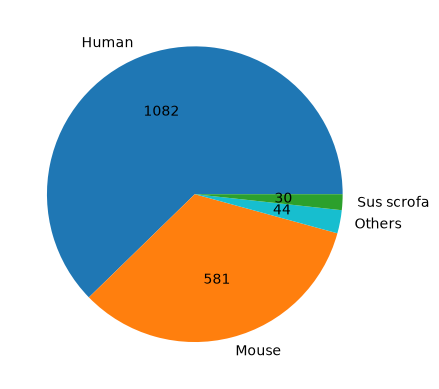

In [102]:
datasets_tmp = datasets_rnaseq[datasets_rnaseq['Dataset']!="E-MTAB-3732"]
species_distr_sample_rnaseq = datasets_tmp.groupby("agg_species_coarse").sum("samples")
species_distr_sample_rnaseq = species_distr_sample_rnaseq.sort_values(by="samples", ascending=False)
fig, ax = plt.subplots()
total_ds = sum(species_distr_sample_rnaseq['samples'])
print(total_ds)
color = [palette_species[x] for x in species_distr_sample_rnaseq.index]
ax.pie(species_distr_sample_rnaseq['samples'], labels=list(species_distr_sample_rnaseq.index), autopct=lambda p: f'{round(p * total_ds / 100):d}', colors=color)

In [103]:
datasets_scrnaseq = datasets[datasets['Technologie']=="scRNAseq"]

97


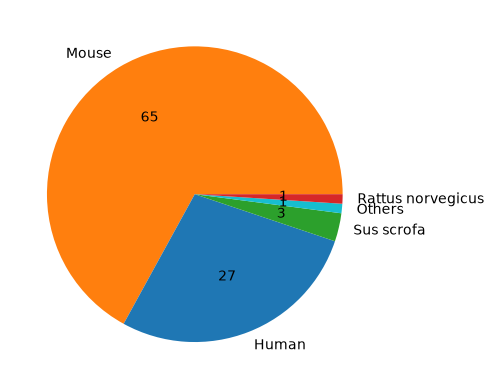

In [104]:
species_distr_scrnaseq = datasets_scrnaseq.groupby("agg_species").size()
species_distr_scrnaseq = species_distr_scrnaseq.sort_values(ascending=False)
fig, ax = plt.subplots()
total_ds = sum(species_distr_scrnaseq.values)
print(total_ds)
color = [palette_species[x] for x in species_distr_scrnaseq.index]
ax.pie(species_distr_scrnaseq.values, labels=list(species_distr_scrnaseq.index), autopct=lambda p: f'{round(p * total_ds / 100):d}', colors=color)

1468


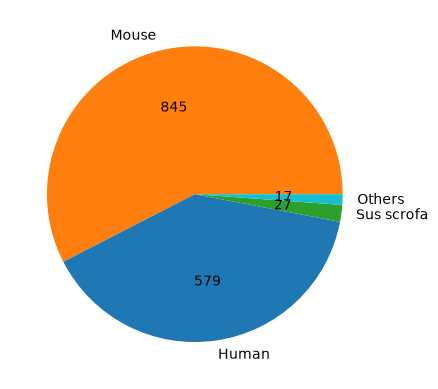

In [105]:
datasets_tmp = datasets_scrnaseq[datasets_scrnaseq['Dataset']!="E-MTAB-3732"]
species_distr_sample_scrnaseq = datasets_tmp.groupby("agg_species_coarse").sum("samples")
species_distr_sample_scrnaseq = species_distr_sample_scrnaseq.sort_values(by="samples", ascending=False)
fig, ax = plt.subplots()
total_ds = sum(species_distr_sample_scrnaseq['samples'])
print(total_ds)
color = [palette_species[x] for x in species_distr_sample_scrnaseq.index]
ax.pie(species_distr_sample_scrnaseq['samples'], labels=list(species_distr_sample_scrnaseq.index), autopct=lambda p: f'{round(p * total_ds / 100):d}', colors=color)

In [106]:
datasets_microarray = datasets[datasets['Technologie']=="Microarray"]

90


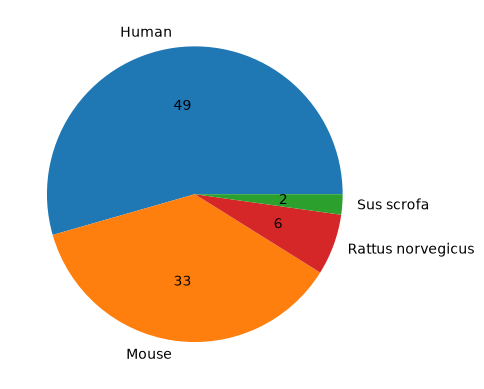

In [107]:
species_distr_microarray = datasets_microarray.groupby("agg_species").size()
species_distr_microarray = species_distr_microarray.sort_values(ascending=False)
fig, ax = plt.subplots()
total_ds = sum(species_distr_microarray.values)
print(total_ds)
color = [palette_species[x] for x in species_distr_microarray.index]
ax.pie(species_distr_microarray.values, labels=list(species_distr_microarray.index), autopct=lambda p: f'{round(p * total_ds / 100):d}', colors=color)

2547


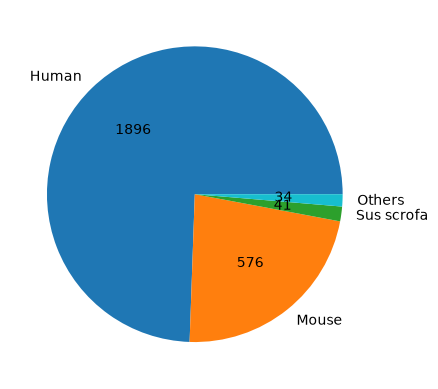

In [108]:
datasets_tmp = datasets_microarray[datasets_microarray['Dataset']!="E-MTAB-3732"]
species_distr_sample_microarray = datasets_tmp.groupby("agg_species_coarse").sum("samples")
species_distr_sample_microarray = species_distr_sample_microarray.sort_values(by="samples", ascending=False)
fig, ax = plt.subplots()
total_ds = sum(species_distr_sample_microarray['samples'])
print(total_ds)
color = [palette_species[x] for x in species_distr_sample_microarray.index]
ax.pie(species_distr_sample_microarray['samples'], labels=list(species_distr_sample_microarray.index), autopct=lambda p: f'{round(p * total_ds / 100):d}', colors=color)

In [109]:
miRNA_microarray = ["Affymetrix miRNA 3.0",
"Agilent miRNA microarray",
"Agilent-070155 Mouse miRNA Microarray",
"Agilent-070156 Human miRNA",
"Ambion Human_Mouse_Rat mirVana miRNA Bioarray_1566V1",
"Agilent-050340 Custom Rat miRNA Microarray",
"Agilent-019159 Rat miRNA",
"Illumina Mouse v2 MicroRNA"
]
datasets_microarray = datasets[datasets['Technologie']=="Microarray"]
datasets_microarray['is_miRNA'] = datasets_microarray['Device'].isin(miRNA_microarray)
datasets_microarray.head()

C:\Users\jonas\AppData\Local\Temp\ipykernel_7872\691975422.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  datasets_microarray['is_miRNA'] = datasets_microarray['Device'].isin(miRNA_microarray)


,index,Dataset,Technologie,Device,Library,Species,samples,plaque phenotype,plaque calcification,location,...,age,comments,celltype,Paper Titel,Experiment,Date,agg_technology,agg_species_coarse,agg_species,is_miRNA
39,NaN,GSE53999,Microarray,GeneChip PrimeView Human Gene Expression Array,NaN,Human,12,NaN,NaN,NaN,...,NaN,NaN,ECs,NF-κB directs dynamic super enhancer formatio...,"ChIP-Seq for various transcription factors, RN...",2014-09-29 00:00:00,Microarray,Human,Human,False
40,NaN,GSE152884,Microarray,Affymetrix Mouse Transcriptome Array 1.0,NaN,Mouse,9,NaN,NaN,Thoracic aortic endothelium,...,NaN,NaN,ECs,MEF2 (Myocyte Enhancer Factor 2) Is Essential ...,"Endothelial-specific, inducible-deletion of Me...",2021-01-11 00:00:00,Microarray,Mouse,Mouse,False
41,NaN,GSE72633,Microarray,Illumina HumanHT-12 v4.0,NaN,Human,9,NaN,NaN,Aortic Ecs,...,NaN,NaN,ECs,Endothelial NOTCH1 is suppressed by circulatin...,Transcript profile from Human Aortic Endotheli...,2015-10-26 00:00:00,Microarray,Human,Human,False
46,NaN,GSE42419,Microarray,Illumina MouseRef-8 v2.0,NaN,Mouse,8,NaN,NaN,NaN,...,NaN,NaN,ECs,Not published,RNA from primary mouse cardiac endothelial cel...,2026-02-26 00:00:00,Microarray,Mouse,Mouse,False
47,NaN,GSE152625,Microarray,Agilent-084555 026652QM_RCUG_HomoSapiens,NaN,Human,4,NaN,NaN,HUVEC,...,NaN,NaN,ECs,Human CD16+ monocytes promote a pro-atheroscle...,RNA of HUVECs from two donors was isolated aft...,2020-08-03 00:00:00,Microarray,Human,Human,False


90


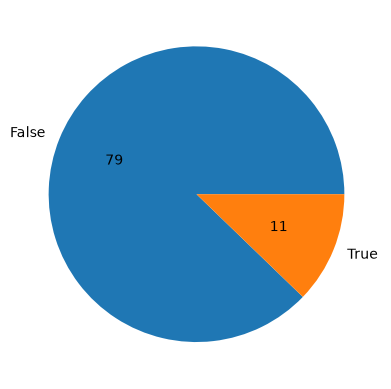

In [110]:
species_distr_microarray_mirna = datasets_microarray.groupby("is_miRNA").size()
species_distr_microarray_mirna = species_distr_microarray_mirna.sort_values(ascending=False)
fig, ax = plt.subplots()
total_ds = sum(species_distr_microarray_mirna.values)
print(total_ds)
#color = [palette_species[x] for x in species_distr_microarray_mirna.index]
ax.pie(species_distr_microarray_mirna.values, labels=list(species_distr_microarray_mirna.index), autopct=lambda p: f'{round(p * total_ds / 100):d}')

In [119]:
used_accessions = [
  'GSE101126',
  'GSE111782',
  'GSE12261',
  'GSE13139',
  'GSE135626',
  'GSE137578',
  'GSE137581',
  'GSE15062',
  'GSE152884',
  'GSE15914',
  'GSE17556',
  'GSE20060',
  'GSE205120',
  'GSE20739',
  'GSE24487',
  'GSE26295',
  'GSE30004',
  'GSE34262',
  'GSE39264',
  'GSE42419',
  'GSE46097',
  'GSE50250',
  'GSE50251',
  'GSE66624',
  'GSE67182',
  'GSE72180',
  'GSE72633',
    "GSE111794",
  "GSE137582",
  "GSE137580",
  "GSE205119",]
len(used_accessions)

31

In [120]:
datasets_microarray_included = datasets[datasets['Dataset'].isin(used_accessions)]
datasets_microarray_included['is_miRNA'] = datasets_microarray_included['Device'].isin(miRNA_microarray)
datasets_microarray_included.head()

C:\Users\jonas\AppData\Local\Temp\ipykernel_7872\3191607776.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  datasets_microarray_included['is_miRNA'] = datasets_microarray_included['Device'].isin(miRNA_microarray)


,index,Dataset,Technologie,Device,Library,Species,samples,plaque phenotype,plaque calcification,location,...,age,comments,celltype,Paper Titel,Experiment,Date,agg_technology,agg_species_coarse,agg_species,is_miRNA
40,NaN,GSE152884,Microarray,Affymetrix Mouse Transcriptome Array 1.0,NaN,Mouse,9,NaN,NaN,Thoracic aortic endothelium,...,NaN,NaN,ECs,MEF2 (Myocyte Enhancer Factor 2) Is Essential ...,"Endothelial-specific, inducible-deletion of Me...",2021-01-11 00:00:00,Microarray,Mouse,Mouse,False
41,NaN,GSE72633,Microarray,Illumina HumanHT-12 v4.0,NaN,Human,9,NaN,NaN,Aortic Ecs,...,NaN,NaN,ECs,Endothelial NOTCH1 is suppressed by circulatin...,Transcript profile from Human Aortic Endotheli...,2015-10-26 00:00:00,Microarray,Human,Human,False
46,NaN,GSE42419,Microarray,Illumina MouseRef-8 v2.0,NaN,Mouse,8,NaN,NaN,NaN,...,NaN,NaN,ECs,Not published,RNA from primary mouse cardiac endothelial cel...,2026-02-26 00:00:00,Microarray,Mouse,Mouse,False
49,NaN,GSE111782,Microarray,Affymetrix Human Genome U133A 2.0 Array,NaN,Human,18,symptomatic vs asymptomatic,NaN,Carotid artery,...,NaN,60-100% stenosis,plaque,Regional Molecular Signature of the Symptomati...,Carotid plaques were collected from 9 symptoma...,2021-03-13 00:00:00,Microarray,Human,Human,False
50,NaN,GSE111794,Microarray,Affymetrix miRNA 3.0,NaN,Human,18,symptomatic vs asymptomatic,NaN,Carotid artery,...,NaN,60-100% stenosis,plaque,Regional Molecular Signature of the Symptomati...,Carotid plaques were collected from 9 symptoma...,2021-03-13 00:00:00,Microarray,Human,Human,True


31


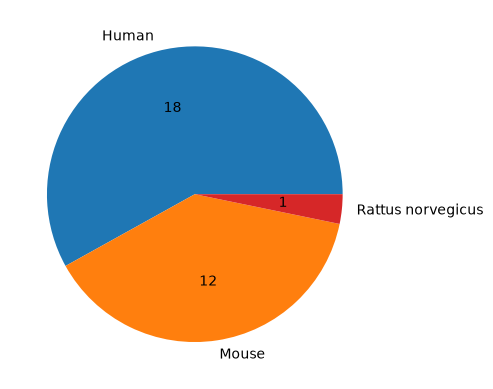

In [121]:
species_distr_microarray = datasets_microarray_included.groupby("agg_species").size()
species_distr_microarray = species_distr_microarray.sort_values(ascending=False)
fig, ax = plt.subplots()
total_ds = sum(species_distr_microarray.values)
print(total_ds)
color = [palette_species[x] for x in species_distr_microarray.index]
ax.pie(species_distr_microarray.values, labels=list(species_distr_microarray.index), autopct=lambda p: f'{round(p * total_ds / 100):d}', colors=color)

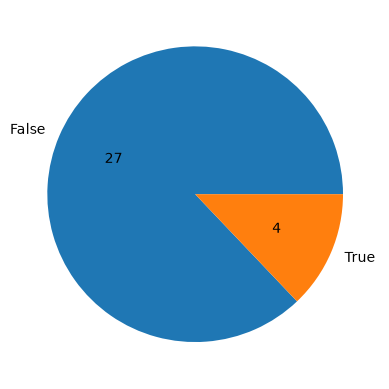

In [122]:
species_distr_microarray = datasets_microarray_included.groupby("is_miRNA").size()
species_distr_microarray = species_distr_microarray.sort_values(ascending=False)
fig, ax = plt.subplots()
total_ds = sum(species_distr_microarray.values)
ax.pie(species_distr_microarray.values, labels=list(species_distr_microarray.index), autopct=lambda p: f'{round(p * total_ds / 100):d}', colors=color)